# 📊 Notebook 1 — Data Exploration & EDA
## AuthentiQ – AI Content Intelligence Platform

Exploratory analysis of **train_v2_drcat_02.csv** — 44,868 texts labelled:
- `0` → Human-written
- `1` → AI-generated

Sources: PERSUADE corpus, Mistral-7B, ChatGPT, LLaMA-2/70B, Falcon-180B, Claude, Palm…

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import re
import warnings
from pathlib import Path
from collections import Counter

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.facecolor': '#0F1117', 'axes.facecolor': '#1A1D27',
    'axes.edgecolor': '#2D3047',   'axes.labelcolor': '#E2E8F0',
    'xtick.color': '#94A3B8',      'ytick.color': '#94A3B8',
    'text.color': '#E2E8F0',       'grid.color': '#2D3047',
    'grid.linestyle': '--',        'grid.alpha': 0.4,
    'figure.dpi': 120,
})

HUMAN_COLOR = '#38BDF8'
AI_COLOR    = '#F472B6'
ACCENT      = '#A78BFA'
print('✅ Libraries loaded')

✅ Libraries loaded


## 1. Load Dataset

In [13]:
DATASET_PATH = Path('../../../dataset/train_v2_drcat_02.csv')
df = pd.read_csv(DATASET_PATH)
print(f'Shape: {df.shape}')
print(f'Columns: {df.columns.tolist()}')
df.head(3)

Shape: (44868, 5)
Columns: ['text', 'label', 'prompt_name', 'source', 'RDizzl3_seven']


,text,label,prompt_name,source,RDizzl3_seven
0,Phones\n\nModern humans today are always on th...,0,Phones and driving,persuade_corpus,False
1,This essay will explain if drivers should or s...,0,Phones and driving,persuade_corpus,False
2,Driving while the use of cellular devices\n\nT...,0,Phones and driving,persuade_corpus,False


In [14]:
print('=== Dataset Info ===')
df.info()
print(f'\nNull values:\n{df.isnull().sum()}')
print(f'\nDuplicate rows: {df.duplicated(subset=["text"]).sum()}')

=== Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44868 entries, 0 to 44867
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   text           44868 non-null  object
 1   label          44868 non-null  int64 
 2   prompt_name    44868 non-null  object
 3   source         44868 non-null  object
 4   RDizzl3_seven  44868 non-null  bool  
dtypes: bool(1), int64(1), object(3)
memory usage: 1.4+ MB

Null values:
text             0
label            0
prompt_name      0
source           0
RDizzl3_seven    0
dtype: int64

Duplicate rows: 0


## 2. Label Distribution

Human (0): 27,371  (61.0%)
AI    (1): 17,497  (39.0%)


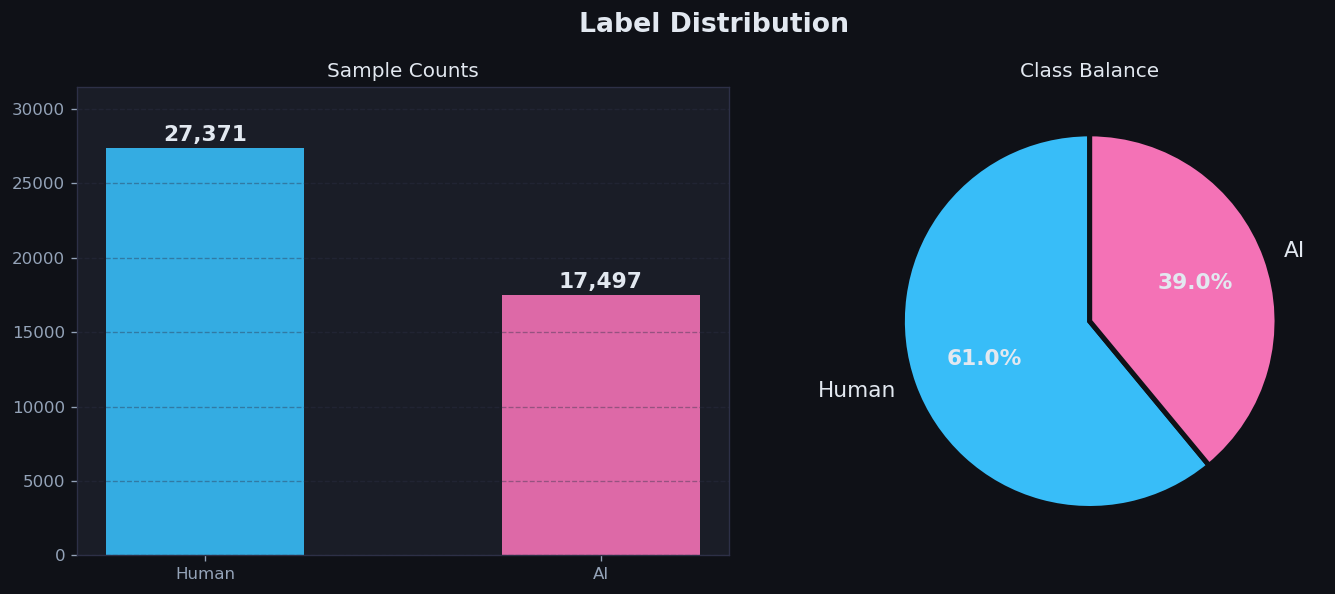

In [15]:
label_counts = df['label'].value_counts()
label_pct    = df['label'].value_counts(normalize=True) * 100
print(f'Human (0): {label_counts[0]:,}  ({label_pct[0]:.1f}%)')
print(f'AI    (1): {label_counts[1]:,}  ({label_pct[1]:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Label Distribution', fontsize=16, fontweight='bold', color='#E2E8F0')

bars = axes[0].bar(['Human', 'AI'], label_counts.values,
                   color=[HUMAN_COLOR, AI_COLOR], width=0.5, edgecolor='none', alpha=0.9)
for bar, count in zip(bars, label_counts.values):
    axes[0].text(bar.get_x()+bar.get_width()/2, bar.get_height()+200,
                 f'{count:,}', ha='center', va='bottom', fontsize=13, color='#E2E8F0', fontweight='bold')
axes[0].set_title('Sample Counts', color='#E2E8F0'); axes[0].grid(axis='y')
axes[0].set_ylim(0, max(label_counts.values)*1.15)

wedges,_,autotexts = axes[1].pie(label_counts.values, labels=['Human','AI'],
    colors=[HUMAN_COLOR,AI_COLOR], autopct='%1.1f%%', startangle=90,
    wedgeprops=dict(edgecolor='#0F1117', linewidth=3),
    textprops={'color':'#E2E8F0','fontsize':13})
for at in autotexts: at.set_fontweight('bold')
axes[1].set_title('Class Balance', color='#E2E8F0')
plt.tight_layout()
plt.savefig('../models/eda_label_dist.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
plt.show()

## 3. Source Distribution

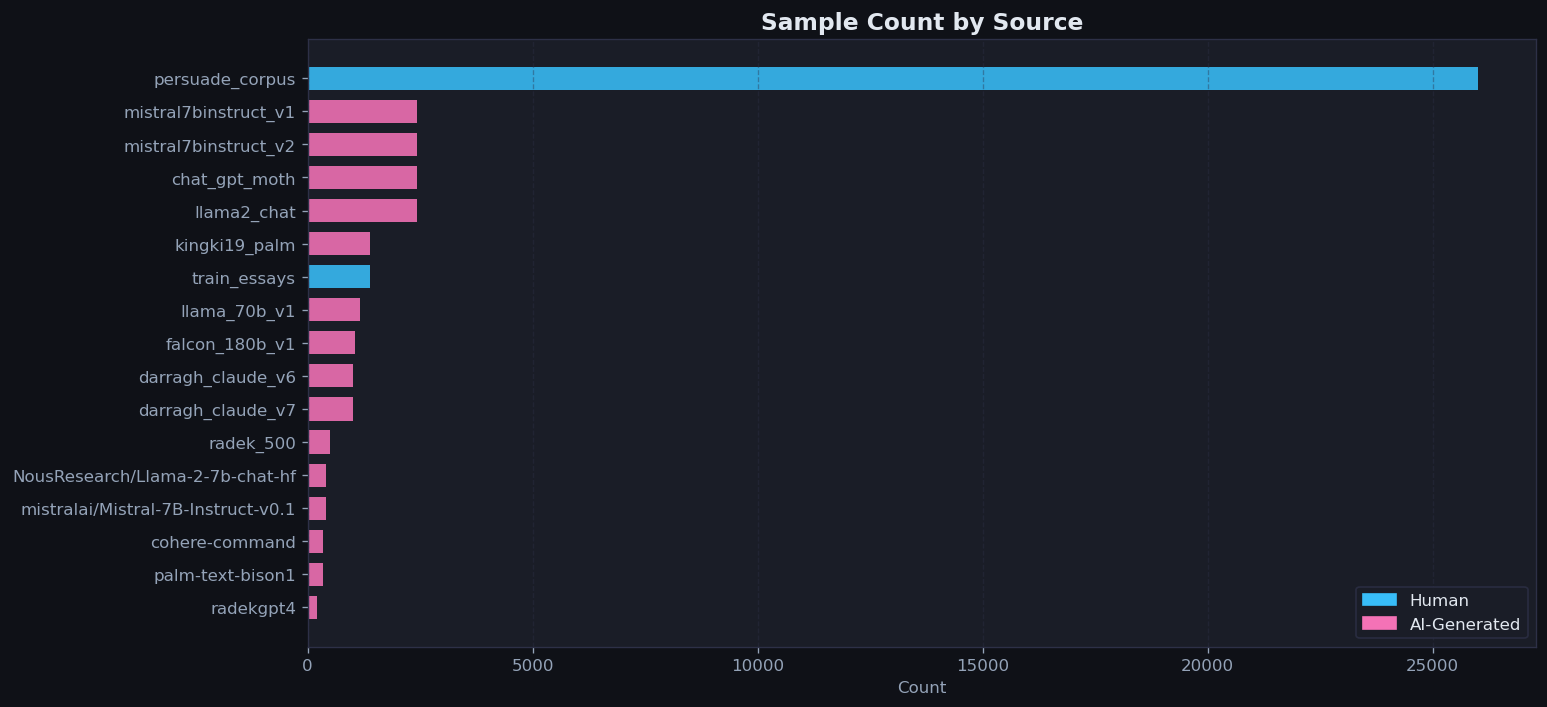

In [16]:
source_counts = df['source'].value_counts()
fig, ax = plt.subplots(figsize=(13, 6))
colors = [HUMAN_COLOR if ('persuade' in s or 'train_essays' in s) else AI_COLOR for s in source_counts.index]
ax.barh(source_counts.index, source_counts.values, color=colors, edgecolor='none', alpha=0.88, height=0.7)
human_p = mpatches.Patch(color=HUMAN_COLOR, label='Human')
ai_p    = mpatches.Patch(color=AI_COLOR,    label='AI-Generated')
ax.legend(handles=[human_p, ai_p], facecolor='#1A1D27', edgecolor='#2D3047')
ax.set_title('Sample Count by Source', fontsize=14, fontweight='bold', color='#E2E8F0')
ax.set_xlabel('Count', color='#94A3B8'); ax.grid(axis='x'); ax.invert_yaxis()
plt.tight_layout()
plt.savefig('../models/eda_source_dist.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
plt.show()

## 4. Text Length Analysis

In [17]:
df['char_len'] = df['text'].str.len()
df['word_len'] = df['text'].str.split().str.len()
df['sent_len'] = df['text'].str.count(r'[.!?]+')
df['avg_word'] = df['char_len'] / (df['word_len'] + 1)
display(df.groupby('label')[['char_len','word_len','sent_len','avg_word']].describe().round(1))

char_len                                                          \
         count    mean     std    min     25%     50%     75%      max   
label                                                                    
0      27371.0  2348.5  1124.5  691.0  1499.5  2132.0  2929.0  18322.0   
1      17497.0  2009.3   603.5   48.0  1650.0  1973.0  2350.0   5078.0   

      word_len         ... sent_len        avg_word                           \
         count   mean  ...      75%    max    count mean  std  min  25%  50%   
label                  ...                                                     
0      27371.0  418.3  ...     27.0  135.0  27371.0  5.6  0.9  4.1  5.3  5.5   
1      17497.0  329.4  ...     21.0   62.0  17497.0  6.1  0.9  4.7  5.7  6.1   

                   
       75%    max  
label              
0      5.8   59.2  
1      6.4  101.6  

[2 rows x 32 columns]

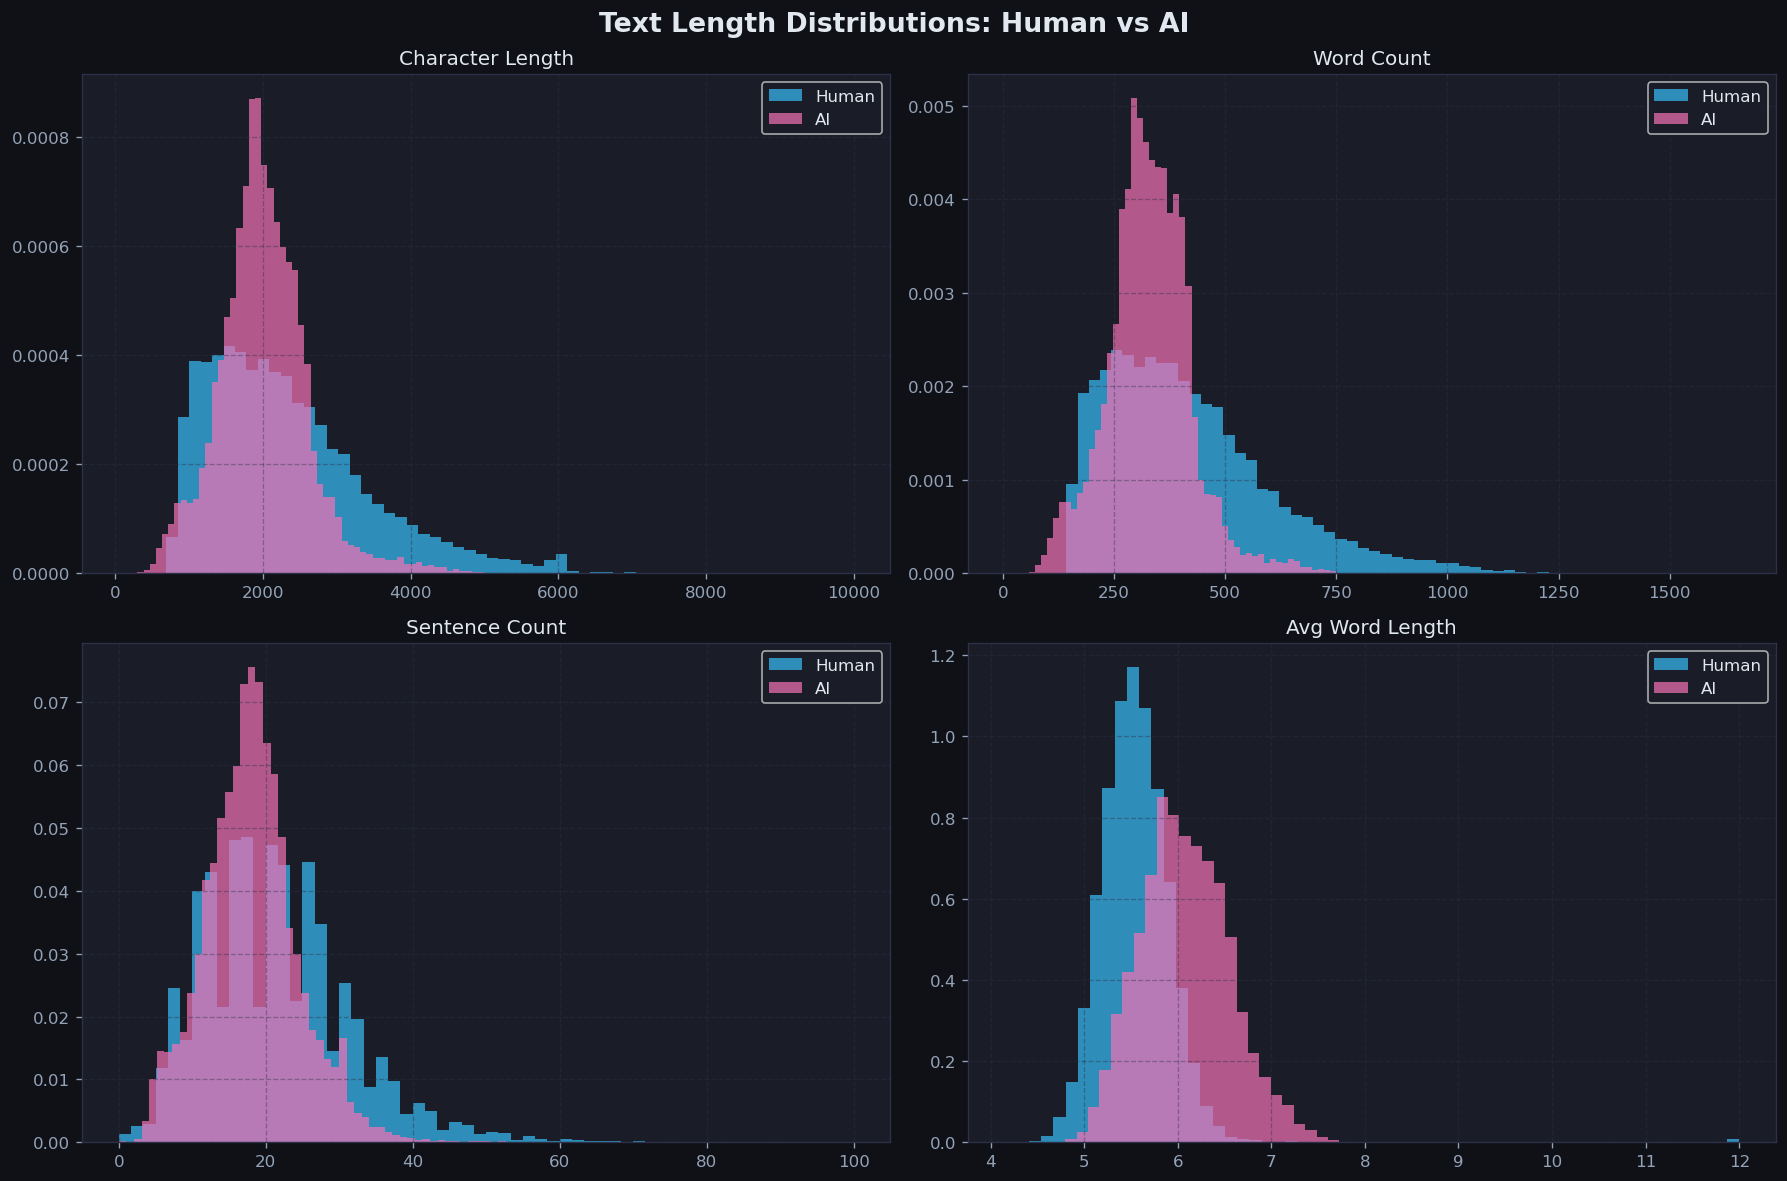

In [18]:
metrics = [('char_len','Character Length',0,10000),('word_len','Word Count',0,2000),
           ('sent_len','Sentence Count',0,100),('avg_word','Avg Word Length',2,12)]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Text Length Distributions: Human vs AI', fontsize=16, fontweight='bold', color='#E2E8F0')
for ax,(col,title,xmin,xmax) in zip(axes.flat, metrics):
    ax.hist(df[df.label==0][col].clip(xmin,xmax), bins=60, alpha=0.7, color=HUMAN_COLOR, label='Human', density=True)
    ax.hist(df[df.label==1][col].clip(xmin,xmax), bins=60, alpha=0.7, color=AI_COLOR,    label='AI',    density=True)
    ax.set_title(title, color='#E2E8F0'); ax.legend(facecolor='#1A1D27'); ax.grid(True)
plt.tight_layout()
plt.savefig('../models/eda_text_lengths.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
plt.show()

## 5. Linguistic Feature Engineering

In [19]:
def extract_features(text):
    words = text.split()
    sentences = [s.strip() for s in re.split(r'[.!?]+', text) if len(s.strip()) > 0]
    sent_lengths = [len(s.split()) for s in sentences]
    return {
        'unique_word_ratio':  len(set(w.lower() for w in words)) / max(len(words),1),
        'comma_density':      text.count(',') / max(len(words),1),
        'excl_density':       text.count('!') / max(len(words),1),
        'sent_burstiness':    np.std(sent_lengths) if len(sent_lengths)>1 else 0,
        'avg_sent_len':       np.mean(sent_lengths) if sent_lengths else 0,
        'furthermore_count':  text.lower().count('furthermore'),
        'additionally_count': text.lower().count('additionally'),
        'moreover_count':     text.lower().count('moreover'),
        'delve_count':        text.lower().count('delve'),
        'overall_count':      text.lower().count('overall'),
        'paragraph_count':    text.count('\n\n') + 1,
    }

print('Extracting linguistic features (may take ~30s)...')
feat_df = pd.DataFrame(df['text'].apply(extract_features).tolist())
feat_df['label'] = df['label'].values
print('✅ Done')
display(feat_df.groupby('label').mean().round(4))

Extracting linguistic features (may take ~30s)...
✅ Done


,unique_word_ratio,comma_density,excl_density,sent_burstiness,avg_sent_len,furthermore_count,additionally_count,moreover_count,delve_count,overall_count,paragraph_count
label,,,,,,,,,,,
0,0.4785,0.0323,0.0007,9.6461,21.4150,0.0383,0.0187,0.0104,0.0008,0.0818,5.3925
1,0.5104,0.0601,0.0017,6.3982,18.7342,0.1459,0.3850,0.0570,0.0027,0.2127,5.8343


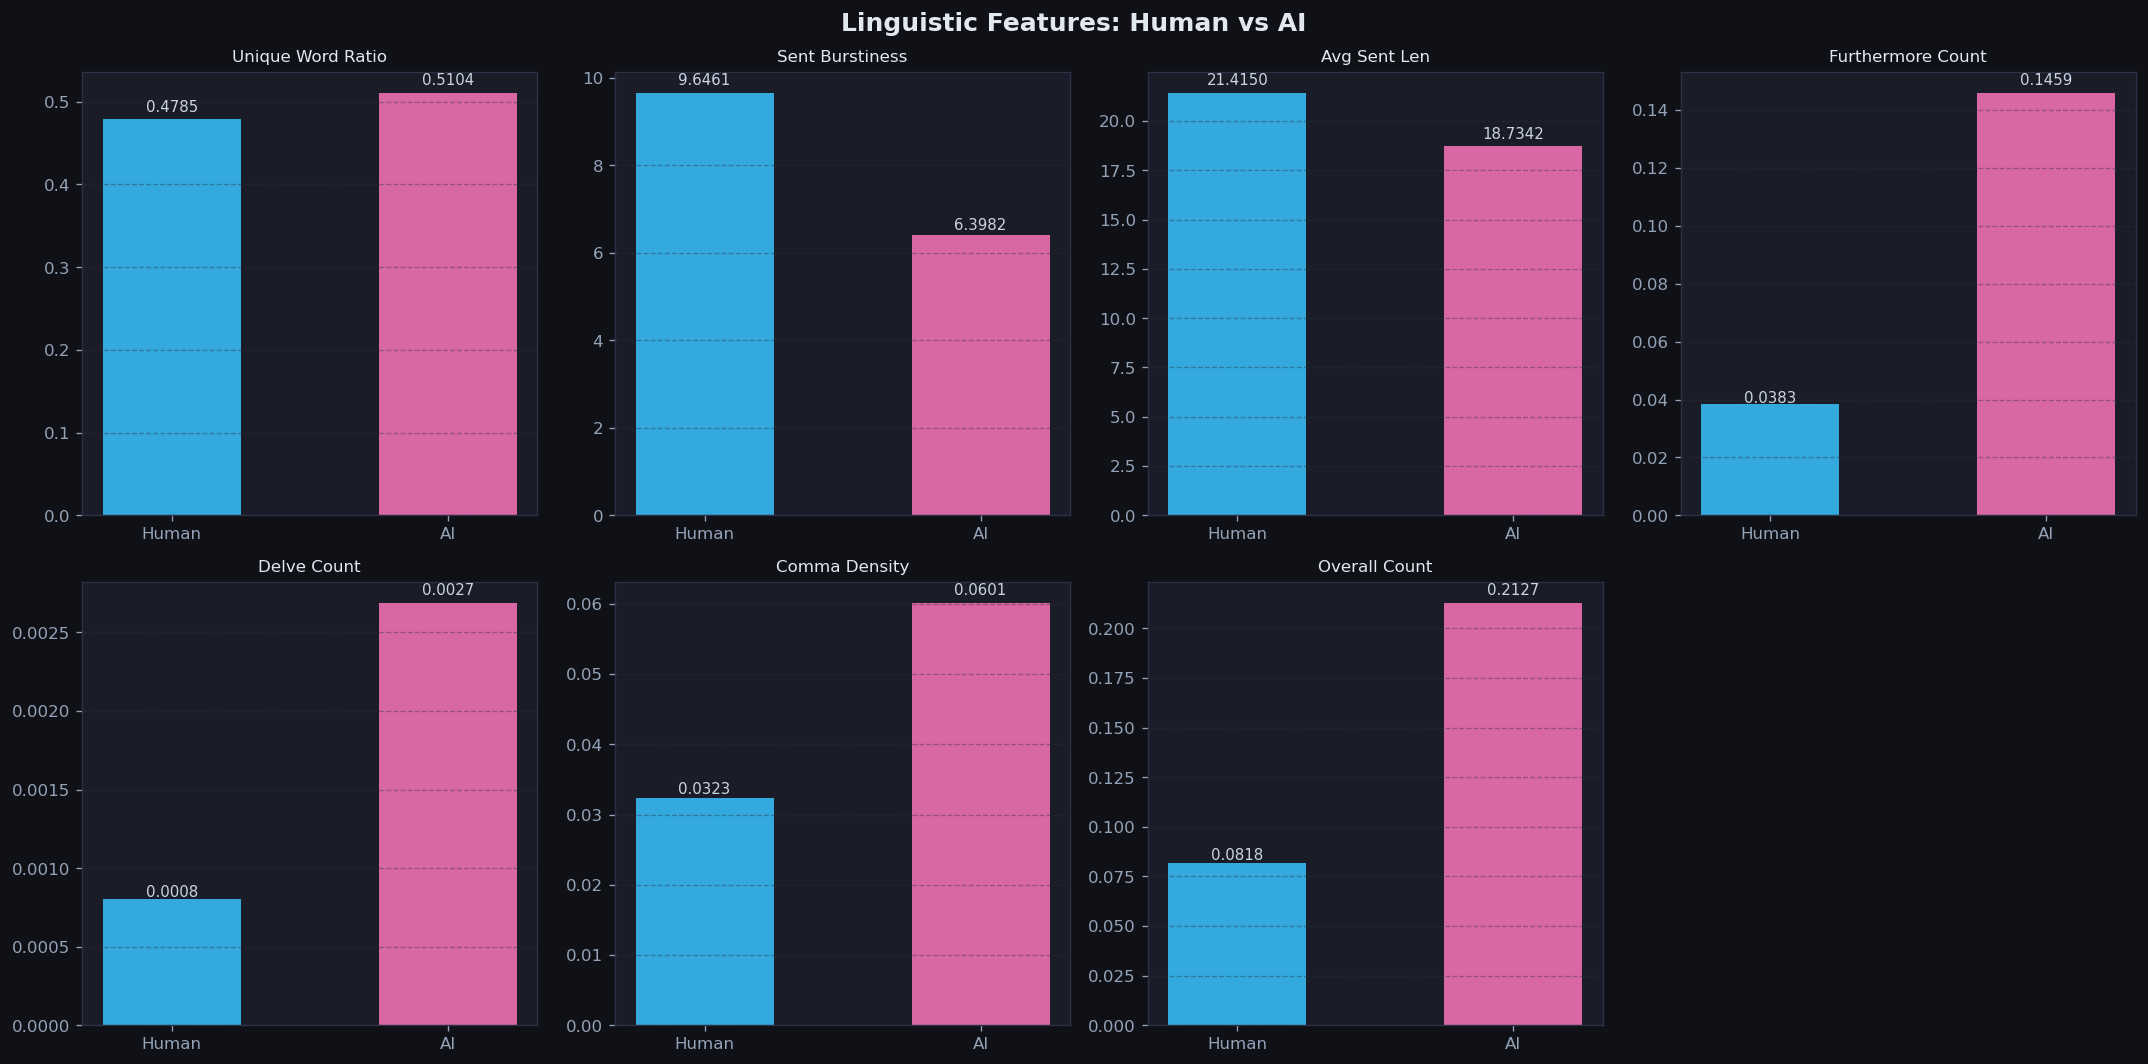

In [20]:
feature_cols = ['unique_word_ratio','sent_burstiness','avg_sent_len',
                'furthermore_count','delve_count','comma_density','overall_count']
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
fig.suptitle('Linguistic Features: Human vs AI', fontsize=15, fontweight='bold', color='#E2E8F0')
for ax, col in zip(axes.flat, feature_cols):
    h_mean = feat_df[feat_df.label==0][col].mean()
    a_mean = feat_df[feat_df.label==1][col].mean()
    bars = ax.bar(['Human','AI'], [h_mean,a_mean], color=[HUMAN_COLOR,AI_COLOR], alpha=0.88, width=0.5)
    ax.set_title(col.replace('_',' ').title(), color='#E2E8F0', fontsize=10); ax.grid(axis='y')
    for bar, val in zip(bars,[h_mean,a_mean]):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()*1.02, f'{val:.4f}', ha='center', fontsize=9, color='#CBD5E1')
axes.flat[-1].set_visible(False)
plt.tight_layout()
plt.savefig('../models/eda_features.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
plt.show()

## 6. Word Log-Odds: AI vs Human Signature Words

Counting word frequencies (may take ~60s)...


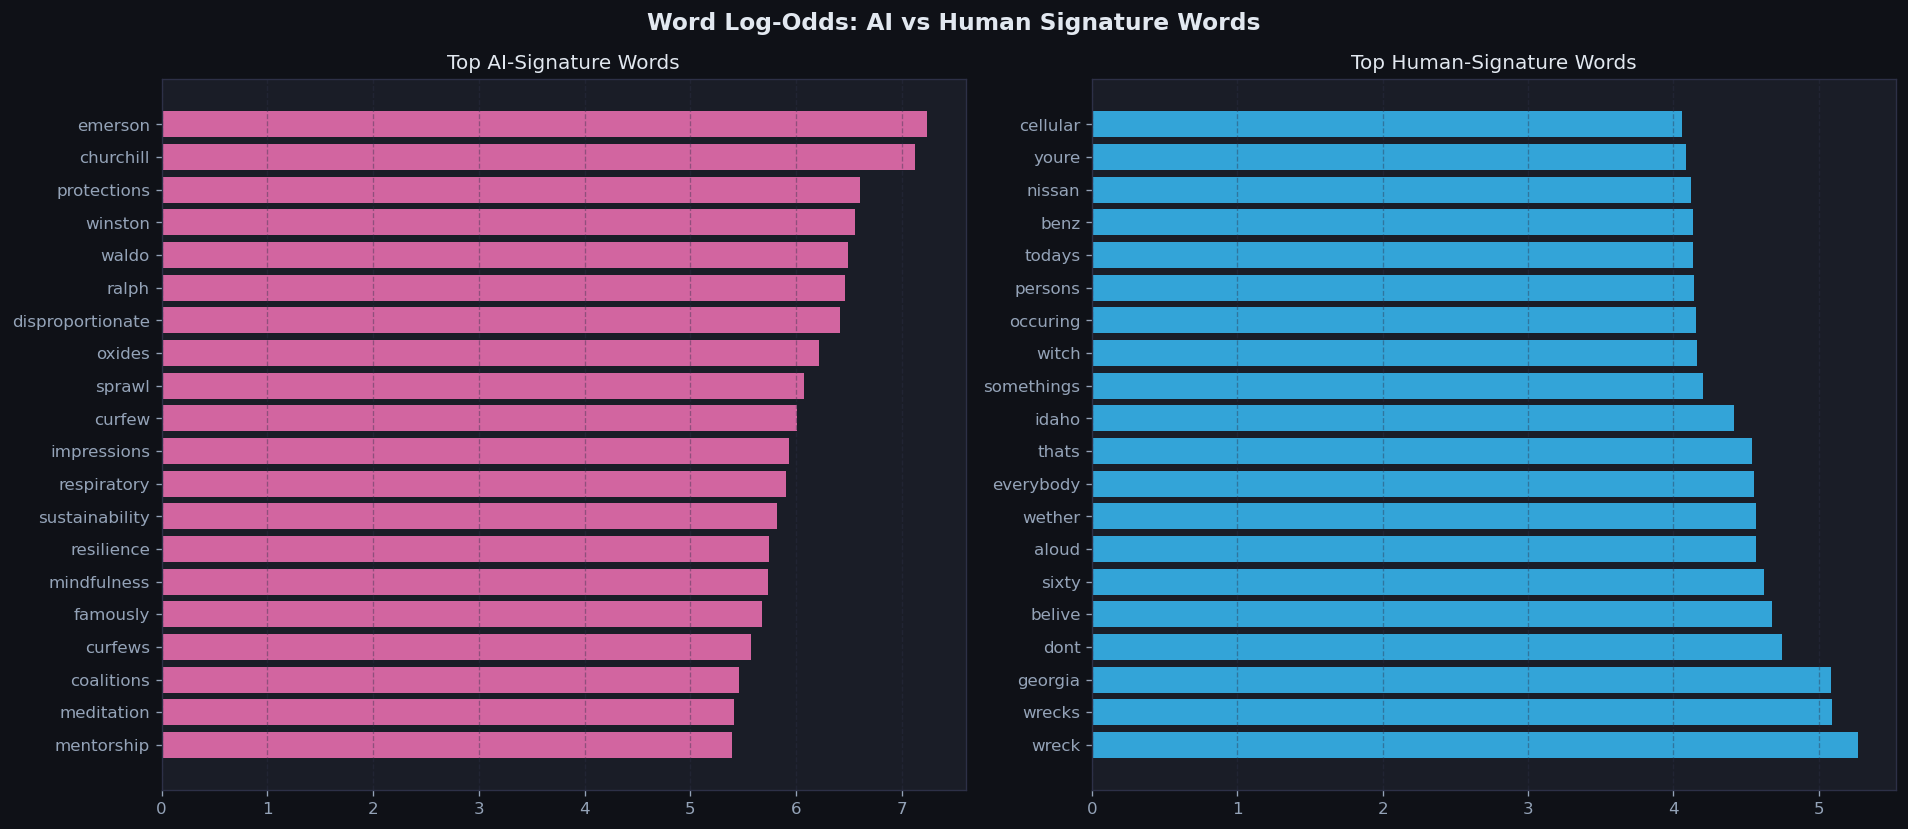


Top AI words: ['emerson', 'churchill', 'protections', 'winston', 'waldo', 'ralph', 'disproportionate', 'oxides', 'sprawl', 'curfew']


In [21]:
def tokenize(text): return re.findall(r'\b[a-z]{4,}\b', text.lower())
print('Counting word frequencies (may take ~60s)...')
human_words, ai_words = Counter(), Counter()
for text, label in zip(df['text'], df['label']):
    tokens = tokenize(str(text))
    (human_words if label==0 else ai_words).update(tokens)

all_words = set(list(human_words)[:5000] + list(ai_words)[:5000])
total_h, total_a = sum(human_words.values()), sum(ai_words.values())
log_odds = {}
for w in all_words:
    p_h = (human_words.get(w,0)+1)/(total_h+len(all_words))
    p_a = (ai_words.get(w,0)+1)/(total_a+len(all_words))
    log_odds[w] = np.log(p_a/p_h)

sorted_lo    = sorted(log_odds.items(), key=lambda x: x[1], reverse=True)
top_ai       = sorted_lo[:20]
top_human    = sorted_lo[-20:]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Word Log-Odds: AI vs Human Signature Words', fontsize=14, fontweight='bold', color='#E2E8F0')

words_ai, scores_ai = zip(*top_ai)
axes[0].barh(words_ai, scores_ai, color=AI_COLOR, alpha=0.85)
axes[0].set_title('Top AI-Signature Words', color='#E2E8F0'); axes[0].invert_yaxis(); axes[0].grid(axis='x')

words_h, scores_h = zip(*top_human)
axes[1].barh(words_h, [-s for _,s in top_human], color=HUMAN_COLOR, alpha=0.85)
axes[1].set_title('Top Human-Signature Words', color='#E2E8F0'); axes[1].invert_yaxis(); axes[1].grid(axis='x')

plt.tight_layout()
plt.savefig('../models/eda_word_logodds.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
plt.show()
print('\nTop AI words:', [w for w,_ in top_ai[:10]])

## 7. Correlation Heatmap

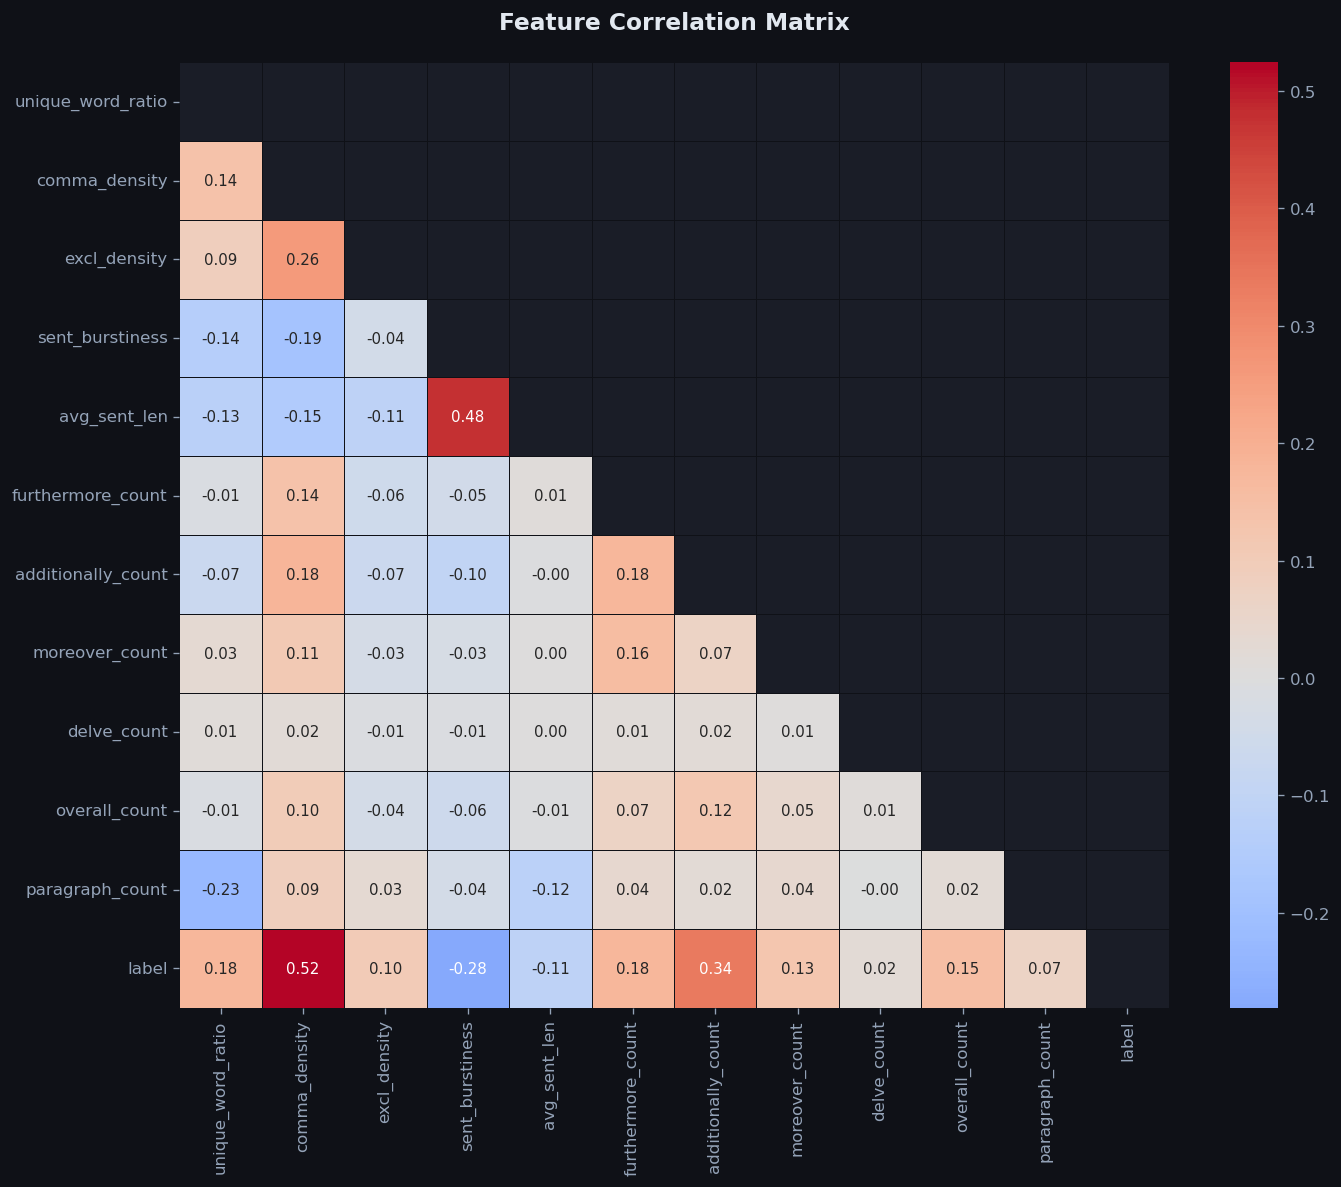

In [22]:
corr = feat_df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax,
            linewidths=0.5, linecolor='#0F1117', annot_kws={'size':9})
ax.set_title('Feature Correlation Matrix', fontsize=14, fontweight='bold', color='#E2E8F0', pad=20)
plt.tight_layout()
plt.savefig('../models/eda_correlation.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
plt.show()

## 8. EDA Summary

| Metric | Human | AI |
|---|---|---|
| Count | 27,371 (61%) | 17,497 (39%) |
| Avg chars | ~2,348 | ~2,009 |
| Unique word ratio | Higher | Lower |
| Sentence burstiness | Higher (varied) | Lower (uniform) |
| 'furthermore' / 'delve' | Rare | Common |

**→ Next: `02_model_training.ipynb`**